In [16]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
mdp = pd.read_csv("11-10-Ali/1000/mdp_evaluation.csv")

dqn = pd.read_csv("11-10-Ali/1000/dqn_evaluation.csv")

training = pd.read_csv("11-10-Ali/training_results.csv")

print("MDP games:", len(mdp))
print("DQN games:", len(dqn))
print("Training episodes:", len(training))

MDP games: 1000
DQN games: 1000
Training episodes: 2000


DQN training progress

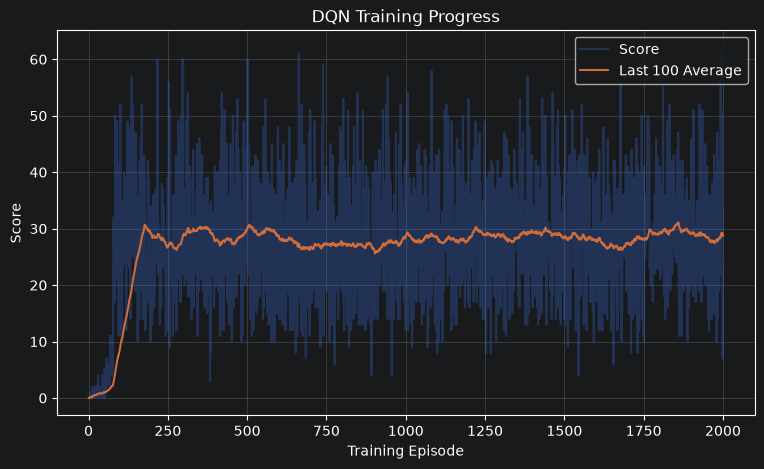

In [18]:
plt.figure(figsize=(9, 5))

plt.plot(
    training["episode"],
    training["score"],
    alpha=0.3,
    label="Score"
)

plt.plot(
    training["episode"],
    training["mean_last_100"],
    label="Last 100 Average"
)

plt.xlabel("Training Episode")
plt.ylabel("Score")
plt.title("DQN Training Progress")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Compare performance of both MDP ,DQN

In [19]:
comparison = pd.DataFrame({
    "Agent": ["MDP Reward", "DQN"],
    "Average Score": [
        mdp["score"].mean(),
        dqn["score"].mean()
    ],
    "Highest Score": [
        mdp["score"].max(),
        dqn["score"].max()
    ],
    "Average Steps": [
        mdp["steps"].mean(),
        dqn["steps"].mean()
    ],
    "Average Reward": [
        mdp["total_reward"].mean(),
        dqn["total_reward"].mean()
    ],
    "Average Number of Steps to Score": [

        mdp["steps"].mean()/
        mdp["score"].mean(),
        dqn["steps"].mean()/
        dqn["score"].mean()
    ],
})

display(comparison.round(2))

,Agent,Average Score,Highest Score,Average Steps,Average Reward,Average Number of Steps to Score
0,MDP Reward,34.60,84,640.49,275.56,18.51
1,DQN,29.31,63,529.27,233.19,18.06


Compare average scores

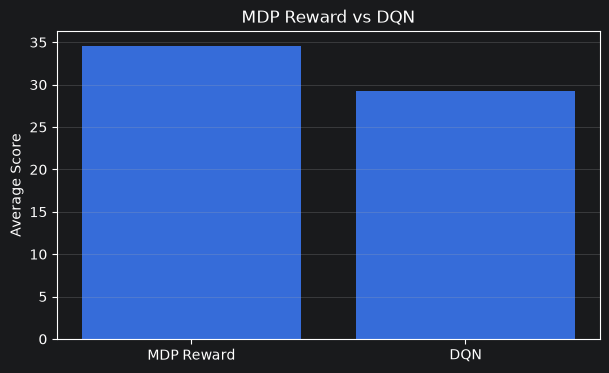

In [20]:
plt.figure(figsize=(7, 4))

plt.bar(
    comparison["Agent"],
    comparison["Average Score"]
)

plt.ylabel("Average Score")
plt.title("MDP Reward vs DQN")
plt.grid(axis="y", alpha=0.3)
plt.show()

Compare game outcomes

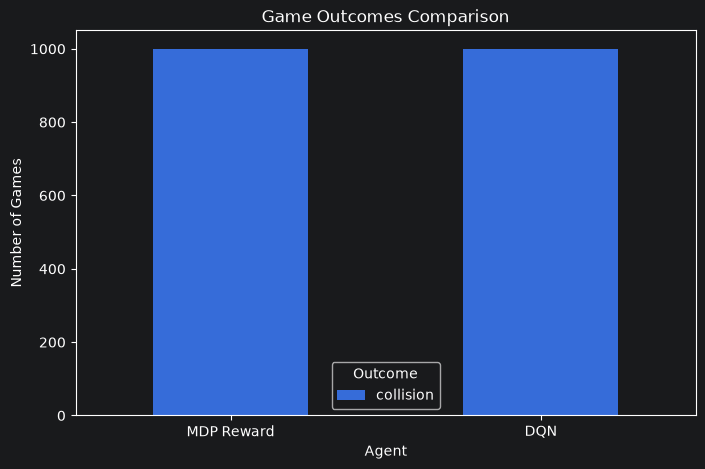

In [21]:
mdp_outcomes = mdp["outcome"].value_counts()
dqn_outcomes = dqn["outcome"].value_counts()

outcomes = pd.DataFrame({
    "MDP Reward": mdp_outcomes,
    "DQN": dqn_outcomes
}).fillna(0)

outcomes.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.xlabel("Agent")
plt.ylabel("Number of Games")
plt.title("Game Outcomes Comparison")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.show()